# TKG3 snow density by layer · 9 July 2021

Compare the archived TKG3 pit profile with native SNOWPACK density layers from the raw and lapse-rate-adjusted HRRR-AK runs. TKG3 has density sample intervals and a recorded seasonal firn boundary at 378 cm. The sheet dates the pit to July 9, which differs from the paper's ground-truth date.

The comparison aligns profiles by **depth below their own snow surface**. The model shows its full simulated column. The observed firn boundary is shown as a depth reference and is not used to identify an equivalent modeled layer. The archived sheet gives no sampling hour or timezone. The figure uses a noon UTC snapshot, and the daily audit shows how much the column depth varies across the 24 available profiles. Change `PROFILE_HOUR_UTC` to inspect another hour on the same date.

In [ ]:
import csv
import mmap
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

root = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'sites/radar_sites/scripts/compare_model_pit_radar.py').is_file()), None)
if root is None:
    raise RuntimeError('Open from inside jif_snow_modeling')
sys.path.insert(0, str(root / 'sites/radar_sites/scripts'))

from compare_model_pit_radar import FORCINGS, load_pits
from prepare_radar_site_forcing import MODEL_ROOT, PERIOD
from visualization import OBSERVATION_COLOR, RC_PARAMS, SIMULATION_COLORS, SIMULATION_LABELS

plt.rcParams.update(RC_PARAMS)
SITE = 'tkg3'
PROFILE_HOUR_UTC = 12
pit = load_pits().loc[SITE]
day = pit.pit_swe_date
snapshot = day + pd.Timedelta(hours=PROFILE_HOUR_UTC)

with Path(pit.source).open(encoding='utf-8-sig', newline='') as stream:
    rows = iter(csv.reader(stream))
    next(row for row in rows if row[:2] == ['Depth (cm)', 'Length (cm)'])
    records = []
    for row in rows:
        if not row[0].strip():
            break
        top, thickness, _, density = map(float, row[:4])
        records.append((top, top + thickness, density * 1000))

pit_layers = pd.DataFrame(records, columns=['top_cm', 'bottom_cm', 'density_kg_m3'])


## Extract the hourly SNOWPACK profiles

Read the profile timestamps and the `0501` (layer-top height) and `0502` (density) records directly from each `.pro` file. Heights are ordered from the base to the surface. Convert them to depth below the modeled surface and retain native layer thickness. These runs have no modeled soil layers.

In [ ]:
def read_snowpack_day(path, day):
    day_prefix = day.strftime('0500,%d.%m.%Y ').encode()
    profiles = {}
    # Locate the date in large profile files without loading the full file into RAM.
    with path.open('rb') as stream, mmap.mmap(stream.fileno(), 0, access=mmap.ACCESS_READ) as data:
        first = data.find(day_prefix)
        if first == -1:
            raise ValueError(f'No profile for {day.date()} in {path}')
        data.seek(first)
        for line in iter(data.readline, b''):
            if line.startswith(b'0500,'):
                if not line.startswith(day_prefix):
                    break
                timestamp = pd.to_datetime(line[5:].decode().strip(), format='%d.%m.%Y %H:%M:%S')
                profiles[timestamp] = {}
            elif line.startswith((b'0501,', b'0502,')):
                field, count, payload = line.split(b',', 2)
                values = np.fromstring(payload.decode(), sep=',')
                if len(values) != int(count):
                    raise ValueError(f'Wrong element count for {timestamp} in {path}')
                profiles[timestamp][field] = values

    layers = {}
    for timestamp, fields in profiles.items():
        heights, densities = fields[b'0501'], fields[b'0502']
        if (len(heights) != len(densities) or not np.all(np.diff(np.r_[0, heights]) > 0)
                or not np.all(np.isfinite(densities) & (densities > 0))):
            raise ValueError(f'Invalid snow height or density for {timestamp} in {path}')
        depth_edges = heights[-1] - np.r_[0, heights][::-1]
        layers[timestamp] = pd.DataFrame({
            'top_cm': depth_edges[:-1],
            'bottom_cm': depth_edges[1:],
            'density_kg_m3': densities[::-1],
        })
    return layers


profiles = {}
audit = []
for forcing in FORCINGS:
    name = f'{forcing}_{SITE}_{PERIOD}_heatflux_soiltemp_zero.pro'
    daily = read_snowpack_day(MODEL_ROOT / SITE / 'output' / name, day)
    if set(daily) != set(pd.date_range(day, periods=24, freq='h')):
        raise ValueError(f'Expected all 24 hourly profiles for {forcing}')
    profile = daily[snapshot]
    profiles[forcing] = profile
    total_depth = [layers.bottom_cm.iloc[-1] for layers in daily.values()]
    audit.append({
        'Simulation': SIMULATION_LABELS[forcing],
        'Snapshot (UTC)': snapshot,
        'Native layers': len(profile),
        'Snapshot depth (cm)': profile.bottom_cm.iloc[-1],
        'Daily min depth (cm)': min(total_depth),
        'Daily max depth (cm)': max(total_depth),
    })
display(pd.DataFrame(audit).round(2))


## Compare profiles and sampling intervals

The left panel shows native model layers and the observed sample intervals. Pit depths are interpreted as the tops of the recorded intervals, consistent with the 370 cm sample extending 8 cm to the firn boundary. Unmeasured intervals are left blank.

The right panel compares each seasonal pit sample with the model averaged over the **same depth interval**, weighting every model layer by its overlap thickness. Intervals deeper than either modeled column are omitted for that run. Positive values indicate denser modeled snow. Matching depths does not imply matching layers or deposition dates.

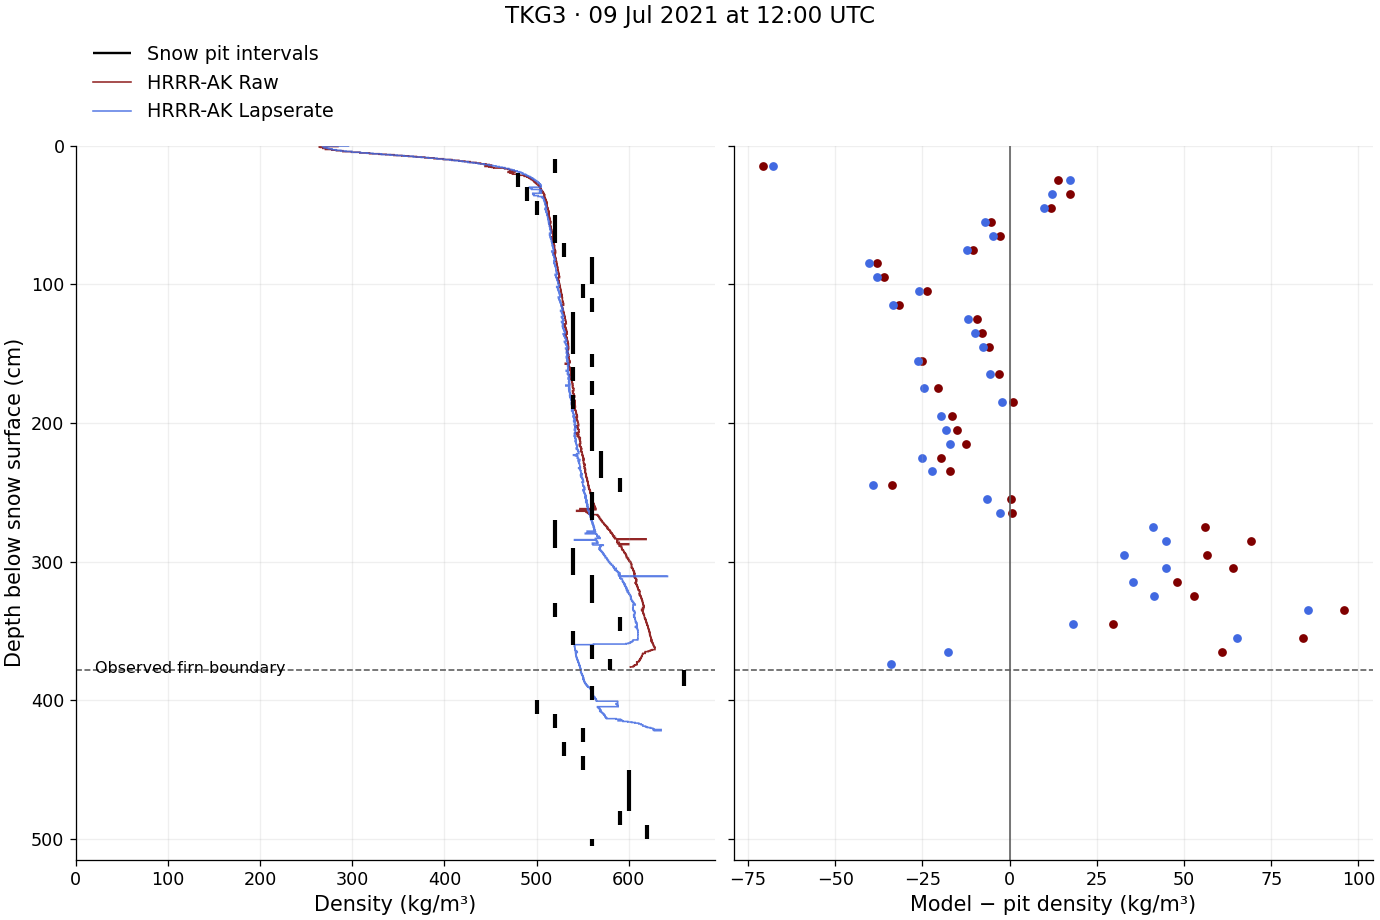

In [ ]:
fig, (profile_ax, difference_ax) = plt.subplots(
    1, 2, figsize=(12, 8), sharey=True, layout='constrained'
)
profile_ax.hlines([], [], [], color=OBSERVATION_COLOR, label='Snow pit intervals')
profile_ax.vlines(pit_layers.density_kg_m3, pit_layers.top_cm, pit_layers.bottom_cm,
                  color=OBSERVATION_COLOR, linewidth=2.6, zorder=4)
firn_depth = pit.depth_cm
seasonal = pit_layers.loc[pit_layers.bottom_cm.le(firn_depth)]

for forcing, layers in profiles.items():
    color = SIMULATION_COLORS[forcing]
    edges = np.r_[layers.top_cm.to_numpy(), layers.bottom_cm.iloc[-1]]
    profile_ax.stairs(layers.density_kg_m3, edges, orientation='horizontal',
                      baseline=None, color=color, label=SIMULATION_LABELS[forcing], alpha=.85)

    matched = seasonal.loc[seasonal.bottom_cm.le(edges[-1])]
    overlaps = np.maximum(
        0, np.minimum(matched.bottom_cm.to_numpy()[:, None], edges[None, 1:])
        - np.maximum(matched.top_cm.to_numpy()[:, None], edges[None, :-1])
    )
    interval_density = overlaps @ layers.density_kg_m3.to_numpy() / overlaps.sum(axis=1)
    difference_ax.scatter(interval_density - matched.density_kg_m3,
                          (matched.top_cm + matched.bottom_cm) / 2, color=color, s=20)

for ax in (profile_ax, difference_ax):
    ax.axhline(firn_depth, color='.35', linestyle='--', lw=1)
    ax.grid(alpha=.2)
difference_ax.axvline(0, color='.35', lw=1)
profile_ax.set(xlabel='Density (kg/m³)', ylabel='Depth below snow surface (cm)',
               ylim=(pit_layers.bottom_cm.max() + 10, 0))
profile_ax.annotate('Observed firn boundary', (.03, firn_depth),
                    xycoords=('axes fraction', 'data'), xytext=(0, -4),
                    textcoords='offset points', va='bottom', fontsize=10)
difference_ax.set(xlabel='Model − pit density (kg/m³)')
profile_ax.legend(loc='lower left', bbox_to_anchor=(0, 1.01), frameon=False)
fig.suptitle(f'{SITE.upper()} · {snapshot:%d %b %Y at %H:%M} UTC')
plt.show()


## Density as snow columns

Each colored band spans the actual thickness of a sampled pit interval or simulated layer. All three columns share a depth axis and continuous density scale. White space represents unsampled depths in the pit or depths below a modeled column. The dashed line marks the observed firn boundary.

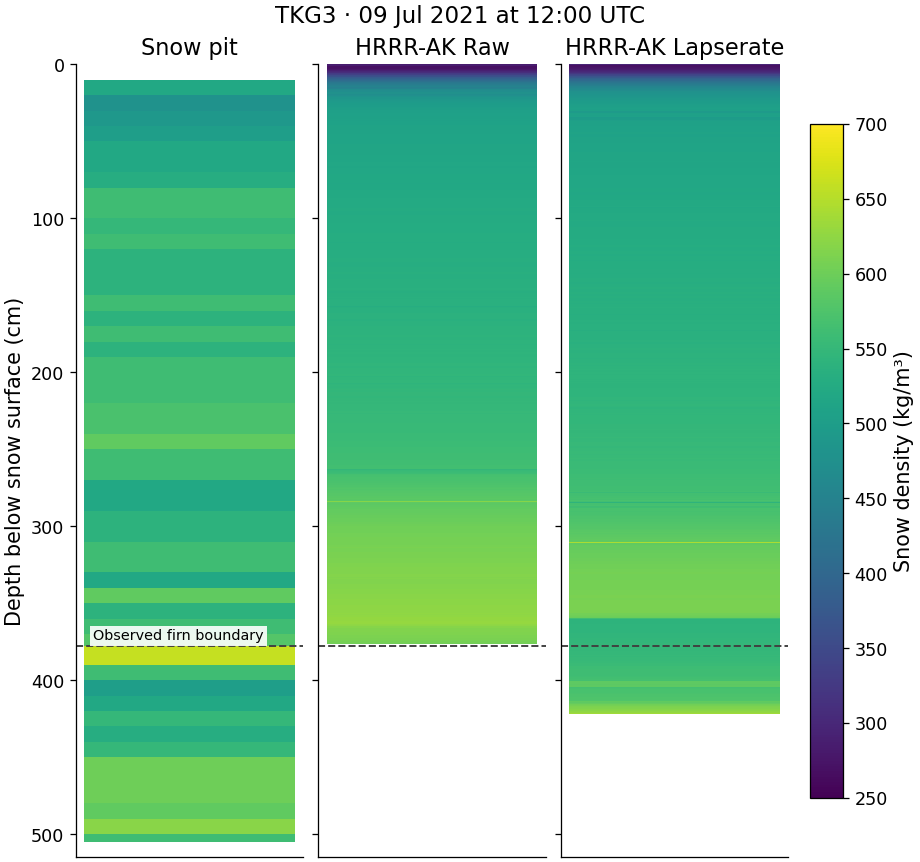

In [ ]:
from matplotlib.collections import PolyCollection
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

columns = {'Snow pit': pit_layers}
columns.update({SIMULATION_LABELS[forcing]: layers for forcing, layers in profiles.items()})
densities = pd.concat([layers.density_kg_m3 for layers in columns.values()])
norm = Normalize(vmin=np.floor(densities.min() / 50) * 50,
                 vmax=np.ceil(densities.max() / 50) * 50)
cmap = 'viridis'

fig_columns, column_axes = plt.subplots(
    1, len(columns), figsize=(8, 7.5), sharey=True, layout='constrained'
)
max_depth = max(layers.bottom_cm.max() for layers in columns.values())
for ax, (label, layers) in zip(column_axes, columns.items()):
    vertices = [[(0, top), (1, top), (1, bottom), (0, bottom)]
                for top, bottom in zip(layers.top_cm, layers.bottom_cm)]
    bands = PolyCollection(vertices, array=layers.density_kg_m3.to_numpy(),
                           cmap=cmap, norm=norm, edgecolors='none', antialiaseds=False)
    ax.add_collection(bands)
    ax.axhline(firn_depth, color='.25', linestyle='--', linewidth=1.2)
    ax.set(title=label, xlim=(-0.04, 1.04), ylim=(max_depth + 10, 0), xticks=[])

column_axes[0].set_ylabel('Depth below snow surface (cm)')
column_axes[0].annotate('Observed firn boundary', (0.02, firn_depth),
                        xytext=(3, 4), textcoords='offset points',
                        bbox=dict(facecolor='white', edgecolor='none', alpha=.9, pad=2),
                        fontsize=9)
fig_columns.colorbar(ScalarMappable(norm=norm, cmap=cmap), ax=column_axes,
                     label='Snow density (kg/m³)', shrink=.85, pad=.03)
fig_columns.suptitle(f'{SITE.upper()} · {snapshot:%d %b %Y at %H:%M} UTC')
plt.show()
